# Mongolian Ger Detection: Training a Single Shot Detector

**Objective.** Train a deep learning object detector that locates Mongolian gers (traditional portable round dwellings) in very-high-resolution satellite imagery. The trained model is the foundation for counting gers by location and date, which turns settlement density in Ulaanbaatar's ger districts into a quantitative signal that can be compared with air pollution and weather data.

**Position in the pipeline.** This is the first of two notebooks.

| Stage | Notebook |
|---|---|
| Problem, training data, model design, training | **01_ger_detection_training.ipynb** (this notebook) |
| Inference and duplicate removal, ger counts, air pollution and weather data, merging and weather normalization | [02_ger_counting_and_air_quality_data.ipynb](02_ger_counting_and_air_quality_data.ipynb) |

**Contents**
1. Problem and Approach
2. Environment Setup
3. Training Data
4. Model Design
5. Training
6. Saving the Model
7. Summary and Next Step

> **Note.** This notebook is a read-only record of the original run on a GPU node of a high-performance computing (HPC) cluster. All outputs are preserved as saved. It cannot be re-executed without the original training chips and computing environment.

## 1. Problem and Approach

Ulaanbaatar experiences some of the most severe winter air pollution among the world's capital cities. A major contributor is household coal burning for heating in the ger districts, the city's expanding peri-urban settlements of traditional gers. Counting gers from satellite imagery provides a measurable proxy for settlement density in these areas, which can then be compared against air pollution and weather data.

Gers are well suited to automated detection: they are small, round, and similar in size and appearance from above. This project uses a **Single Shot Detector (SSD)** from `arcgis.learn`, a single-stage detector built on fastai and PyTorch. A single-stage design predicts boxes and classes in one pass, which keeps inference practical over large image scenes that contain many objects of a single class.

## 2. Environment Setup

### 2.1 Library Versions

Record the versions of the deep learning stack used for training. These versions (ArcGIS API for Python, fastai v1, PyTorch) date from around 2020, and the `arcgis.learn` interfaces used below depend on them.

In [10]:
%%time
from arcgis.gis import GIS
gis = GIS()
# gis = GIS("url", "username", "password")

import arcgis
from arcgis.learn import SingleShotDetector, prepare_data
import fastai
import torch
import torchvision

print("arcgis API version =", arcgis.__version__)
print("fastai version =", fastai.__version__)
print("torch version =", torch.__version__)
print("torchvision version =", torchvision.__version__)

arcgis API version = 1.8.5
fastai version = 1.0.60
torch version = 1.4.0
torchvision version = 0.5.0
CPU times: user 315 µs, sys: 0 ns, total: 315 µs
Wall time: 324 µs


### 2.2 GPU Availability Check

Confirm that PyTorch can see a CUDA device and allocate a tensor on it. Training an SSD on roughly 20,000 labeled objects is impractical on CPU, so this check guards against silently falling back to CPU.

In [11]:
torch.cuda.is_available()

True

In [12]:
torch.zeros((3, 224, 224)).cuda()

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]],

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]],

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]], device='cuda:0')

**What this shows.** `torch.cuda.is_available()` returns `True`, and the test tensor is created on `cuda:0`, so training runs on the GPU.

## 3. Training Data

### 3.1 Loading the Labeled Training Chips

Approximately 20,000 ger instances were labeled and exported from ArcGIS Pro as training chips (small image tiles with bounding-box labels). `prepare_data()` reads the exported folder, splits it into training and validation sets, and serves it in mini-batches. The dataset has a single class, `ger`.

`prepare_data()` can also apply data augmentation such as random rotation, scaling, and flipping. Augmentation could alternatively be configured directly with fastai transforms.

In [13]:
data = prepare_data('training_chips/Training_Output', {1: '  ger'})

### 3.2 Inspecting Labeled Samples

Before training, `show_batch()` displays a random batch of chips with their labeled boxes. This is a quick check that the labels line up with the objects they mark.

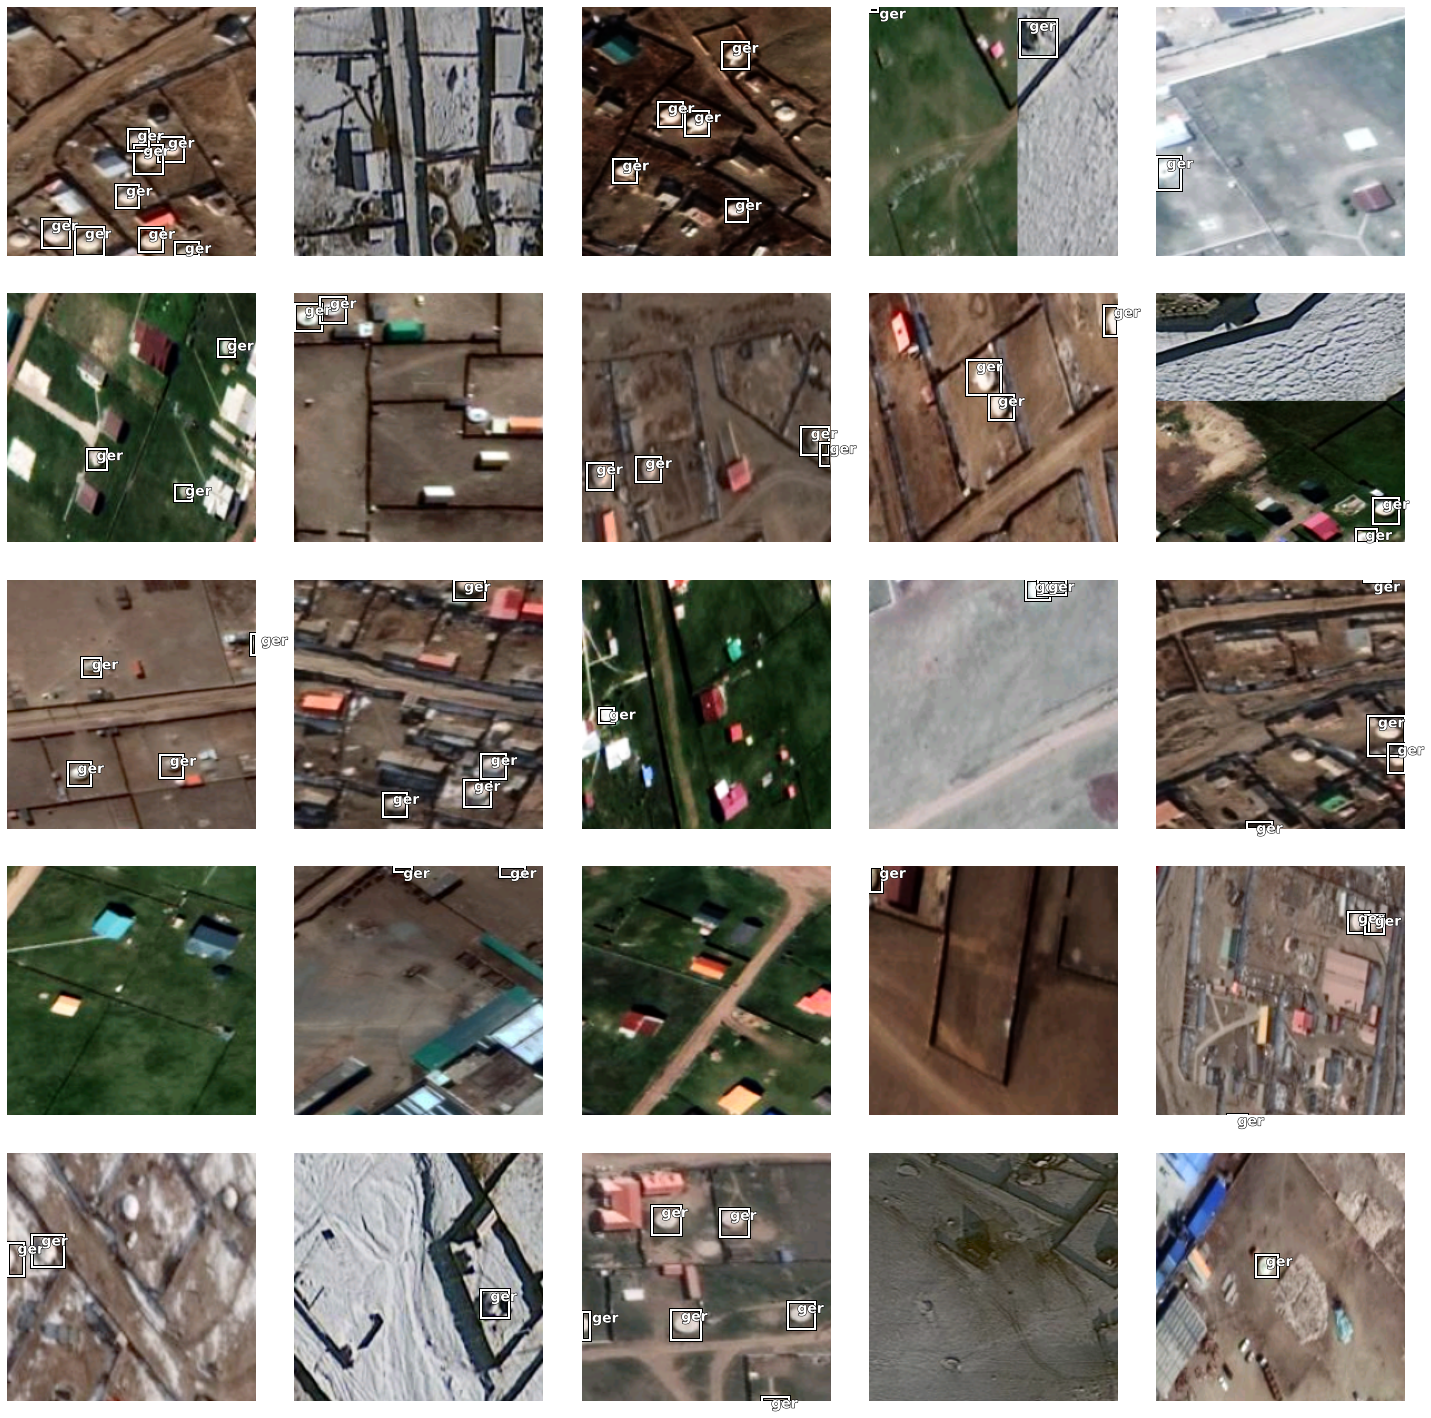

In [14]:
data.show_batch()

**What this shows.** The 5 x 5 grid shows chips with white `ger` boxes drawn around small, round, light-colored structures. The chips vary in season and surface: snow-covered ground, bare soil, and green vegetation all appear. Some chips contain several gers among fenced plots and rectangular buildings, some contain one or two, and some contain none. Several boxes sit at chip edges, where a ger is only partly visible.

## 4. Model Design

### 4.1 SSD Configuration

The SSD is configured with a single 9 x 9 anchor grid (`grids=[9]`), one zoom level (`zooms=[1.0]`), and one square aspect ratio (`ratio=[[1.0, 1.0]]`). Gers are round and similar in size, so one square anchor shape at one scale matches the target object without the extra anchors a multi-shape, multi-scale configuration would add.

In [15]:
from arcgis.learn import SingleShotDetector

ssd = SingleShotDetector(data, grids=[9], zoomes=[1.0], ratio=[[1.0, 1.0]])

## 5. Training

### 5.1 Learning-Rate Finder

The learning rate is the most influential training hyperparameter. A learning rate that is too small makes training slow and computationally wasteful, and one that is too large prevents the model from settling into a low loss. `lr_find()` (from fastai, exposed through `arcgis.learn`) trains briefly while increasing the learning rate and records the loss, then suggests a value.

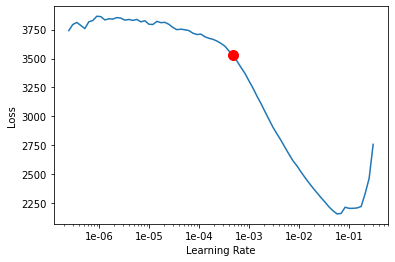

0.0004786300923226385

In [16]:
ssd.lr_find()

**What this shows.** The loss stays roughly flat (about 3,750 to 3,850) at learning rates below about 1e-4. It then falls steadily to a minimum just below 1e-1 and rises sharply after that. The red marker shows the suggested value, **4.79e-4** (returned as `0.0004786300923226385`), which lies at the start of the steep descent. This value is used for training below.

### 5.2 Training for 15 Epochs

`fit()` trains the model for 15 epochs at the learning rate found above, using fastai's one-cycle schedule. The SSD starts from a pretrained backbone: the newly added detection layers are trained and the earlier layers are fine-tuned. Training and validation loss are reported each epoch. Rising validation loss would indicate overfitting to the training chips.

In [17]:
#here we are training the model for 15 epochs with chosen learning rate
ssd.fit(15, lr=0.0004786300923226385)

epoch,train_loss,valid_loss,time
0,1524.312012,969.265991,04:12
1,699.629395,823.290344,01:48
2,552.395508,700.041504,01:48
3,473.766327,632.270935,01:48
4,421.861847,579.957886,01:48
5,397.886230,577.418457,01:48
6,382.480713,525.337891,01:49
7,375.309204,519.226990,01:49
8,365.803955,512.167847,01:48
9,363.969055,512.614380,01:48


**What this shows.** Validation loss falls from **969.3** after the first epoch to a minimum of **494.4** at epoch 13 (495.1 at epoch 14). Most of the improvement happens in the first seven epochs. After about epoch 10 the curve flattens, with changes of only a few units per epoch. Validation loss does not rise, so the log shows no sign of overfitting within 15 epochs. Training loss follows the same pattern, from 1,524.3 down to about 352 to 356. The first epoch took 4:12 and each later epoch about 1:48.

A plot of these saved values is available at [`assets/training_loss_curve.png`](../assets/training_loss_curve.png).

### 5.3 Visual Check of Predictions

`show_results()` compares ground-truth boxes (left column) with model predictions (right column) on validation chips. No formal detection metric such as mAP was computed in this project, so this side-by-side view is the main qualitative check of model behavior. A very low display threshold (`thresh=0.05`) is used here so that low-confidence detections are also shown.

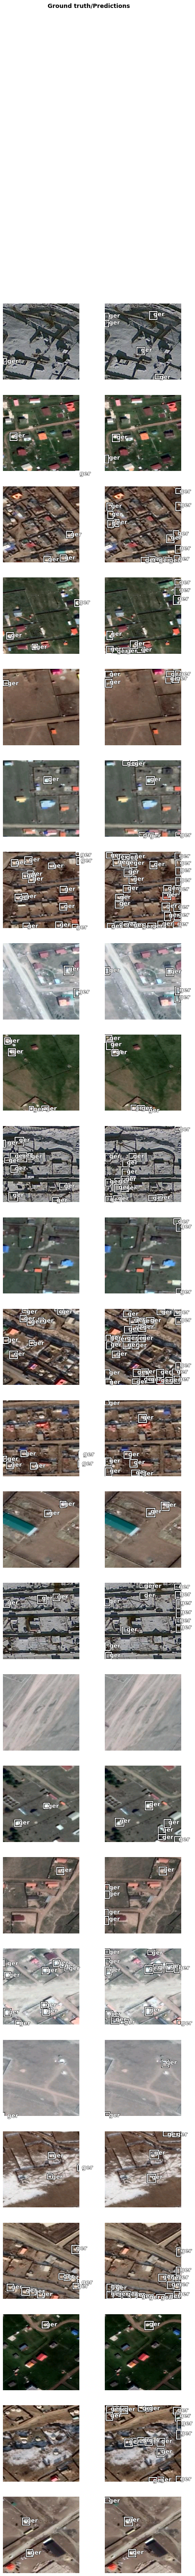

In [18]:
ssd.show_results(rows=25, thresh=0.05)

**What this shows.** The predicted boxes generally fall on the same small round structures as the ground-truth boxes. At this low display threshold, the prediction column contains noticeably more boxes than the ground truth. Some are clusters of overlapping boxes on a single object, and some are boxes along the chip edges. This shows why inference in notebook 02 uses a higher confidence threshold, non-maximum suppression, and an additional duplicate-removal step.

## 6. Saving the Model

The trained model is saved as an Esri model definition (`.emd`) together with its weights. Notebook 02 loads this file to detect and count gers in new satellite imagery.

In [ ]:
ssd.save("mongolian_ger_detecting_model")

## 7. Summary and Next Step

**Produced in this notebook**
- An SSD ger detector trained on approximately 20,000 labeled ger instances exported from ArcGIS Pro, using a single square anchor shape suited to round, similarly sized objects.
- A learning rate of 4.79e-4 selected with the learning-rate finder, and 15 epochs of GPU training during which validation loss fell from 969.3 to about 495 and plateaued after about epoch 10.
- A qualitative check of predictions against ground truth. No formal metric such as mAP was computed.
- The saved model `mongolian_ger_detecting_model`.

**Next step.** [02_ger_counting_and_air_quality_data.ipynb](02_ger_counting_and_air_quality_data.ipynb) applies this model to imagery of ger-district and non-ger-district sites, removes duplicate detections, and produces ger counts by location and date. It then assembles the air pollution and weather data that the counts are compared against.